🔹 CELL 1: Imports

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
from torch.utils.data import Dataset
import torchvision.transforms as T


🔹 CELL 2: Dataset Overview + Base Path

In [2]:
# Dataset base path (Kaggle)
base_path = '/kaggle/input/brisc2025/brisc2025'

print("Dataset Root:", base_path)


Dataset Root: /kaggle/input/brisc2025/brisc2025


🔹 CELL 3: Folder & File Structure

In [3]:
def show_folder_structure(path, level=1):
    for root, dirs, files in os.walk(path):
        depth = root.replace(path, '').count(os.sep)
        if depth < level:
            print(root.replace(path, ''))
            for f in files[:5]:
                print("  ", f)

show_folder_structure(base_path)



   manifest.json
   README.md
   manifest.csv
   manifest.json.sha256
   manifest.csv.sha256


CELL 4: Load Manifest + Label Distribution (Classification)

In [4]:
# Load manifest
df = pd.read_csv(os.path.join(base_path, 'manifest.csv'))

print("Manifest Shape:", df.shape)
display(df.head())


Manifest Shape: (15586, 16)


,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...


Label Distribution (Bar Chart)

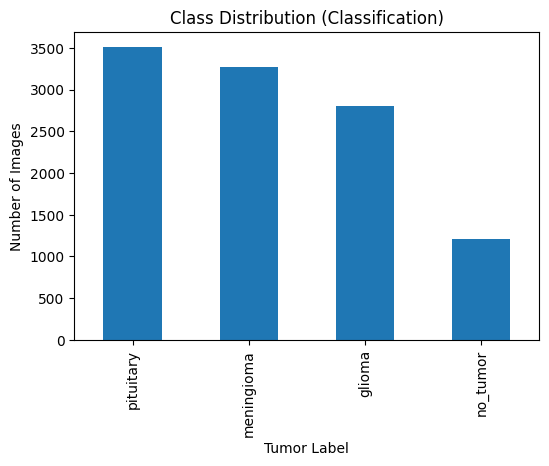

In [5]:
label_counts = df[df['is_mask'] == False]['tumor_label'].value_counts()

plt.figure(figsize=(6,4))
label_counts.plot(kind='bar')
plt.title("Class Distribution (Classification)")
plt.xlabel("Tumor Label")
plt.ylabel("Number of Images")
plt.show()


CELL 5: Image–Mask Merge (Segmentation Pairing)

In [6]:
# Path clean
df['relative_path'] = df['relative_path'].str.replace('\\', '/', regex=False)
df['linked_image'] = df['linked_image'].str.replace('\\', '/', regex=False)

# Separate masks & images
masks_df = df[df['is_mask'] == True].copy()
images_df = df[df['is_mask'] == False].copy()

# Extract filename from linked_image
masks_df['image_filename'] = masks_df['linked_image'].apply(
    lambda x: os.path.basename(str(x))
)

# Merge mask with corresponding image
merged_df = pd.merge(
    masks_df[['relative_path', 'tumor_label', 'image_filename']], 
    images_df[['relative_path', 'filename']], 
    left_on='image_filename', 
    right_on='filename', 
    suffixes=('_mask', '_image')
)

print("Total Image–Mask Pairs:", len(merged_df))
display(merged_df.head())


Total Image–Mask Pairs: 9586


,relative_path_mask,tumor_label,image_filename,relative_path_image,filename
0,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00001_gl_ax_t1.jpg,classification_task/test/glioma/brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg
1,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00001_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00001_gl_ax_t1.jpg
2,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00002_gl_ax_t1.jpg,classification_task/test/glioma/brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg
3,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00002_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00002_gl_ax_t1.jpg
4,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00003_gl_ax_t1.jpg,classification_task/test/glioma/brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg


🔹 CELL 6: Sample Visualization (Image + Mask)

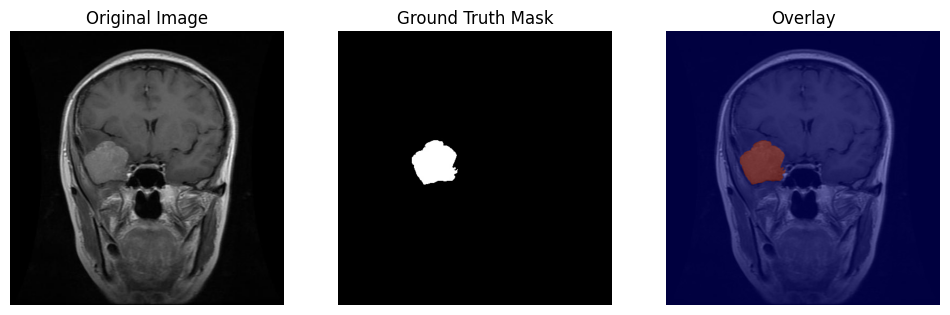

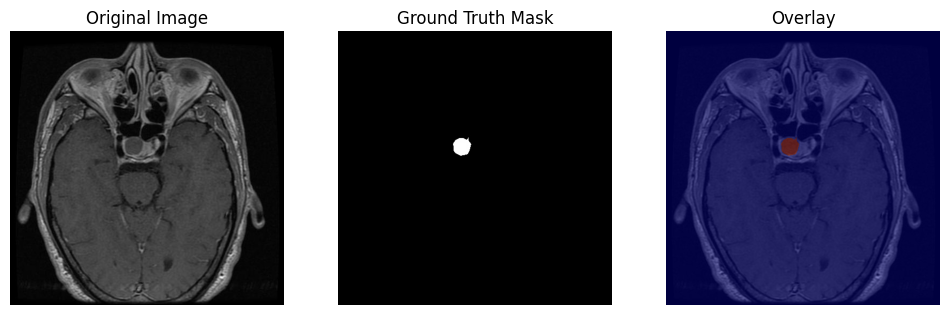

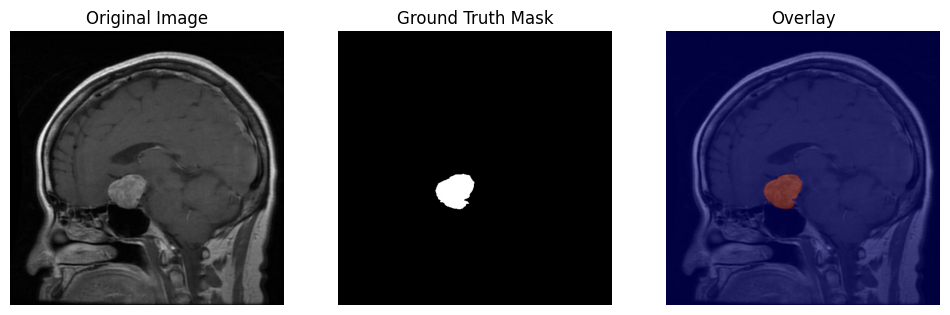

In [7]:
def visualize_sample(df, idx=0):
    img_path = os.path.join(base_path, df.iloc[idx]['relative_path_image'])
    mask_path = os.path.join(base_path, df.iloc[idx]['relative_path_mask'])

    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(image)
    plt.imshow(mask, cmap='jet', alpha=0.5)
    plt.title("Overlay")
    plt.axis('off')

    plt.show()

# Show 3 samples
for i in range(3):
    visualize_sample(merged_df, idx=random.randint(0, len(merged_df)-1))


🔹 CELL 7: Segmentation Mask Analysis (Foreground vs Background)

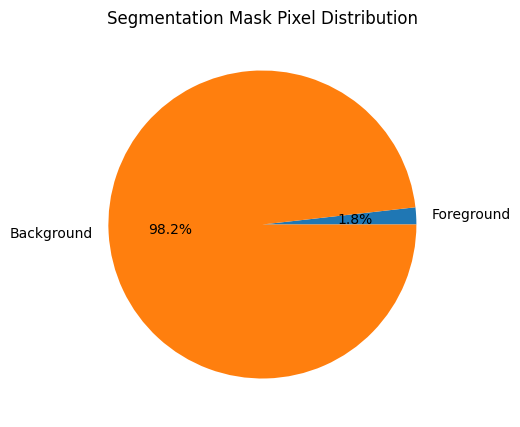

In [8]:
def mask_pixel_stats(df, samples=50):
    fg_pixels = 0
    bg_pixels = 0

    for i in range(samples):
        idx = random.randint(0, len(df)-1)
        mask_path = os.path.join(base_path, df.iloc[idx]['relative_path_mask'])
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        fg_pixels += np.sum(mask > 0)
        bg_pixels += np.sum(mask == 0)

    return fg_pixels, bg_pixels

fg, bg = mask_pixel_stats(merged_df)

plt.figure(figsize=(5,5))
plt.pie([fg, bg], labels=['Foreground', 'Background'], autopct='%1.1f%%')
plt.title("Segmentation Mask Pixel Distribution")
plt.show()


🔹 CELL 8: Image Size & Channel Analysis

In [9]:
heights = []
widths = []
channels = []

for i in range(50):
    img_path = os.path.join(base_path, merged_df.iloc[i]['relative_path_image'])
    img = cv2.imread(img_path)
    h, w, c = img.shape
    heights.append(h)
    widths.append(w)
    channels.append(c)

print("Unique image sizes:", set(zip(heights, widths)))
print("Channels used:", set(channels))


Unique image sizes: {(512, 512)}
Channels used: {3}


🔹 CELL 9: Preprocessing + Augmentation Strategy

In [10]:
IMG_SIZE = 256

# Preprocessing (used for val/test)
basic_transform = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])

# Augmentation (used only for training)
train_transform = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(15),
    T.ToTensor(),
])


🔹 CELL 10: Train / Validation / Test Split

In [11]:
train_df, temp_df = train_test_split(
    merged_df,
    test_size=0.3,
    random_state=42,
    stratify=merged_df['tumor_label']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df['tumor_label']
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")


Train: 6710 | Val: 1438 | Test: 1438


Segmentation rows only (filter)

In [12]:
# segmentation training এর জন্য শুধু segmentation_task/.../images রাখা
seg_df = merged_df[ merged_df['relative_path_image'].str.contains('segmentation_task') ].reset_index(drop=True)

print("Original merged_df:", len(merged_df))
print("Segmentation-only seg_df:", len(seg_df))
display(seg_df.head())


Original merged_df: 9586
Segmentation-only seg_df: 4793


,relative_path_mask,tumor_label,image_filename,relative_path_image,filename
0,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00001_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00001_gl_ax_t1.jpg
1,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00002_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00002_gl_ax_t1.jpg
2,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00003_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00003_gl_ax_t1.jpg
3,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00004_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00004_gl_ax_t1.jpg
4,segmentation_task/test/masks/brisc2025_test_00...,glioma,brisc2025_test_00005_gl_ax_t1.jpg,segmentation_task/test/images/brisc2025_test_0...,brisc2025_test_00005_gl_ax_t1.jpg


Mask unique values চেক (confirm binary)

In [13]:
import numpy as np, os, cv2

mask_path = os.path.join(base_path, seg_df.iloc[0]['relative_path_mask'])
m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
print("unique mask values:", np.unique(m)[:20])


unique mask values: [  0   1   2   3   4   5   7 248 249 250 251 252 253 254 255]


In [14]:
#Train/Val/Test split (segmentation জন্য)
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    seg_df, test_size=0.3, random_state=42, stratify=seg_df['tumor_label']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df['tumor_label']
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")


Train: 3355 | Val: 719 | Test: 719


In [15]:
#PyTorch Segmentation Dataset
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import numpy as np
import cv2, os

IMG_SIZE = 256

# image transforms
img_tf_train = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(15),
    T.ToTensor()
])

img_tf_val = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor()
])

class SegmentationDataset(Dataset):
    def __init__(self, df, base_path, img_transform=None):
        self.df = df.reset_index(drop=True)
        self.base_path = base_path
        self.img_transform = img_transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = os.path.join(self.base_path, self.df.iloc[idx]['relative_path_image'])
        mask_path = os.path.join(self.base_path, self.df.iloc[idx]['relative_path_mask'])

        # read image (BGR->RGB)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # read mask grayscale
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # resize mask to IMG_SIZE (important)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

        # binary mask: 0/255 -> 0/1
        mask = (mask > 0).astype(np.float32)

        if self.img_transform is not None:
            image = self.img_transform(image)
        else:
            image = T.ToTensor()(image)

        # mask tensor: (1,H,W)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


In [16]:
# DataLoaders (FIXED for Kaggle)
BATCH_SIZE = 4   # 8 → 4 (lighter for Attention U-Net)

train_ds = SegmentationDataset(train_df, base_path, img_transform=img_tf_train)
val_ds   = SegmentationDataset(val_df, base_path, img_transform=img_tf_val)
test_ds  = SegmentationDataset(test_df, base_path, img_transform=img_tf_val)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("Train batches:", len(train_loader), "Val batches:", len(val_loader))


Train batches: 839 Val batches: 180


torch.Size([4, 3, 256, 256]) torch.Size([4, 1, 256, 256])


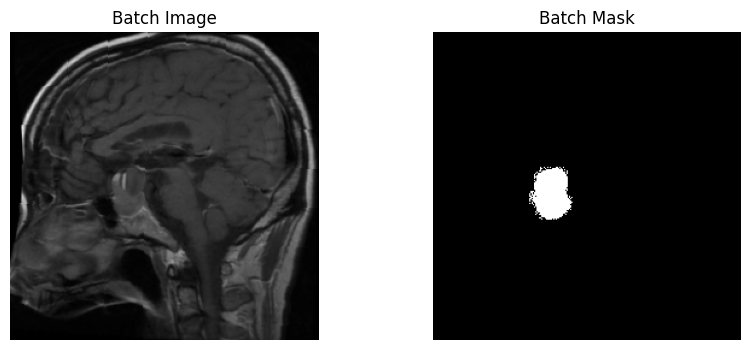

In [17]:
#Quick sanity check (1 batch visualize)
import matplotlib.pyplot as plt

x, y = next(iter(train_loader))
print(x.shape, y.shape)

img = x[0].permute(1,2,0).numpy()
msk = y[0][0].numpy()

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(img); plt.title("Batch Image"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(msk, cmap="gray"); plt.title("Batch Mask"); plt.axis("off")
plt.show()


In [18]:
import torch
print(torch.cuda.get_device_name(0))


Tesla P100-PCIE-16GB


In [19]:
#Device + helper
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [20]:
#U-Net Model
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64,128,256,512]):
        super().__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Down part
        ch = in_channels
        for f in features:
            self.downs.append(DoubleConv(ch, f))
            ch = f

        # Bottleneck
        self.bottleneck = DoubleConv(features[-1], features[-1]*2)

        # Up part
        for f in reversed(features):
            self.ups.append(nn.ConvTranspose2d(f*2, f, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(f*2, f))

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for i in range(0, len(self.ups), 2):
            x = self.ups[i](x)  # upsample
            skip = skip_connections[i//2]

            # if size mismatch (rare), fix by interpolation
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)

            x = torch.cat((skip, x), dim=1)
            x = self.ups[i+1](x)

        return self.final_conv(x)  # logits


In [21]:
#Loss (BCEWithLogits + Dice)
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        intersection = (probs * targets).sum(dim=1)
        dice = (2*intersection + self.smooth) / (probs.sum(dim=1) + targets.sum(dim=1) + self.smooth)
        return 1 - dice.mean()

bce = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()

def combined_loss(logits, targets, dice_weight=1.0, bce_weight=1.0):
    return dice_weight * dice_loss(logits, targets) + bce_weight * bce(logits, targets)


In [22]:
#Metrics (Dice, IoU, Pixel Accuracy)
import numpy as np

@torch.no_grad()
def compute_metrics(logits, masks, thresh=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > thresh).float()

    # flatten
    preds_f = preds.view(preds.size(0), -1)
    masks_f = masks.view(masks.size(0), -1)

    # Dice
    inter = (preds_f * masks_f).sum(dim=1)
    dice = (2*inter + eps) / (preds_f.sum(dim=1) + masks_f.sum(dim=1) + eps)

    # IoU
    union = (preds_f + masks_f - preds_f*masks_f).sum(dim=1)
    iou = (inter + eps) / (union + eps)

    # Pixel accuracy
    correct = (preds == masks).float().mean(dim=[1,2,3])

    return dice.mean().item(), iou.mean().item(), correct.mean().item()


In [23]:
#Training + Validation Loop
from tqdm import tqdm

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    total_dice, total_iou, total_acc = 0, 0, 0

    for images, masks in tqdm(loader, leave=False):
        images = images.to(device)
        masks  = masks.to(device)

        optimizer.zero_grad()
        logits = model(images)

        loss = combined_loss(logits, masks)
        loss.backward()
        optimizer.step()

        dice, iou, acc = compute_metrics(logits.detach(), masks)
        total_loss += loss.item()
        total_dice += dice
        total_iou  += iou
        total_acc  += acc

    n = len(loader)
    return total_loss/n, total_dice/n, total_iou/n, total_acc/n


@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval()
    total_loss = 0
    total_dice, total_iou, total_acc = 0, 0, 0

    for images, masks in tqdm(loader, leave=False):
        images = images.to(device)
        masks  = masks.to(device)

        logits = model(images)
        loss = combined_loss(logits, masks)

        dice, iou, acc = compute_metrics(logits, masks)
        total_loss += loss.item()
        total_dice += dice
        total_iou  += iou
        total_acc  += acc

    n = len(loader)
    return total_loss/n, total_dice/n, total_iou/n, total_acc/n


In [24]:
#Run Training (save best model)
import matplotlib.pyplot as plt

model = UNet(in_channels=3, out_channels=1).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 8  # 1-2 দিনের জন্য এটুকু enough (চাইলে 10-15)

history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": [],
    "train_iou": [], "val_iou": [],
    "train_acc": [], "val_acc": []
}

best_val_dice = -1

for epoch in range(1, EPOCHS+1):
    tr_loss, tr_dice, tr_iou, tr_acc = train_one_epoch(model, train_loader, optimizer)
    va_loss, va_dice, va_iou, va_acc = validate_one_epoch(model, val_loader)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_dice"].append(tr_dice); history["val_dice"].append(va_dice)
    history["train_iou"].append(tr_iou);   history["val_iou"].append(va_iou)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)

    print(f"Epoch {epoch}/{EPOCHS} | "
          f"Train Loss {tr_loss:.4f} Dice {tr_dice:.4f} IoU {tr_iou:.4f} Acc {tr_acc:.4f} || "
          f"Val Loss {va_loss:.4f} Dice {va_dice:.4f} IoU {va_iou:.4f} Acc {va_acc:.4f}")

    # save best
    if va_dice > best_val_dice:
        best_val_dice = va_dice
        torch.save(model.state_dict(), "unet_seg_best.pt")
        print("✅ Saved: unet_seg_best.pt (best val dice)")


Epoch 1/8 | Train Loss 1.1640 Dice 0.1860 IoU 0.1317 Acc 0.9678 || Val Loss 0.9739 Dice 0.4181 IoU 0.3009 Acc 0.9776
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 2/8 | Train Loss 0.9161 Dice 0.3363 IoU 0.2417 Acc 0.9732 || Val Loss 0.7023 Dice 0.5111 IoU 0.3913 Acc 0.9843
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 3/8 | Train Loss 0.7763 Dice 0.3792 IoU 0.2827 Acc 0.9772 || Val Loss 0.5656 Dice 0.5712 IoU 0.4450 Acc 0.9843
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 4/8 | Train Loss 0.7130 Dice 0.4081 IoU 0.3100 Acc 0.9777 || Val Loss 0.4964 Dice 0.5963 IoU 0.4855 Acc 0.9884
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 5/8 | Train Loss 0.6836 Dice 0.4264 IoU 0.3278 Acc 0.9785 || Val Loss 0.4483 Dice 0.6385 IoU 0.5281 Acc 0.9889
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 6/8 | Train Loss 0.6672 Dice 0.4359 IoU 0.3379 Acc 0.9790 || Val Loss 0.4278 Dice 0.6493 IoU 0.5384 Acc 0.9891
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 7/8 | Train Loss 0.6443 Dice 0.4545 IoU 0.3538 Acc 0.9794 || Val Loss 0.4213 Dice 0.6617 IoU 0.5476 Acc 0.9888
✅ Saved: unet_seg_best.pt (best val dice)


Epoch 8/8 | Train Loss 0.6419 Dice 0.4574 IoU 0.3559 Acc 0.9788 || Val Loss 0.4149 Dice 0.6569 IoU 0.5390 Acc 0.9885


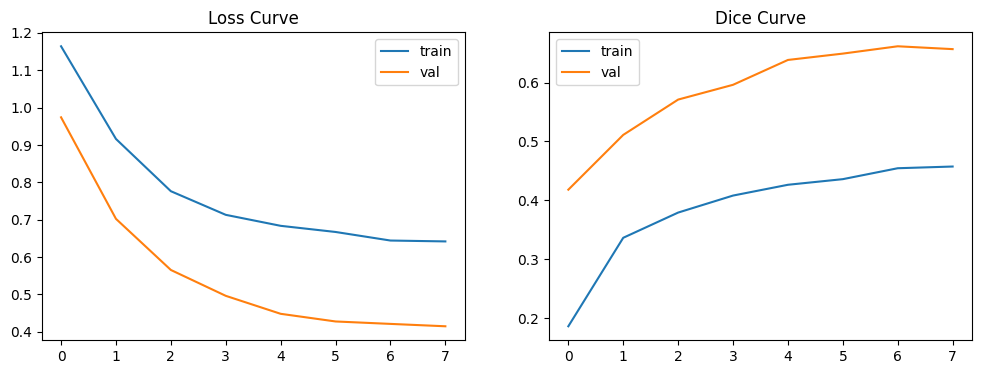

In [25]:
#Plot Curves (Loss + Dice)
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.title("Loss Curve")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_dice"], label="train")
plt.plot(history["val_dice"], label="val")
plt.title("Dice Curve")
plt.legend()

plt.show()


In [26]:
#Test Evaluation (final metrics)
# load best model
model.load_state_dict(torch.load("unet_seg_best.pt", map_location=device))

test_loss, test_dice, test_iou, test_acc = validate_one_epoch(model, test_loader)
print(f"TEST | Loss {test_loss:.4f} Dice {test_dice:.4f} IoU {test_iou:.4f} PixelAcc {test_acc:.4f}")


TEST | Loss 0.4052 Dice 0.6774 IoU 0.5603 PixelAcc 0.9887


In [27]:
#Classification dataframe
# classification images only (is_mask=False)
cls_df = df[df['is_mask'] == False].copy()

# path clean (আগে করলেও সমস্যা নেই)
cls_df['relative_path'] = cls_df['relative_path'].str.replace('\\','/', regex=False)

# classification_task এর image গুলো রাখি (safe)
cls_df = cls_df[cls_df['relative_path'].str.contains('classification_task')].reset_index(drop=True)

print("Total classification images:", len(cls_df))
print(cls_df[['relative_path','tumor_label']].head())
print("Labels:", cls_df['tumor_label'].unique())


Total classification images: 6000
                                       relative_path tumor_label
0  classification_task/test/glioma/brisc2025_test...      glioma
1  classification_task/test/glioma/brisc2025_test...      glioma
2  classification_task/test/glioma/brisc2025_test...      glioma
3  classification_task/test/glioma/brisc2025_test...      glioma
4  classification_task/test/glioma/brisc2025_test...      glioma
Labels: ['glioma' 'meningioma' 'no_tumor' 'pituitary']


In [28]:
#Label encoding (string → number)
label_names = sorted(cls_df['tumor_label'].unique())
label2id = {name:i for i,name in enumerate(label_names)}
id2label = {i:name for name,i in label2id.items()}

cls_df['label_id'] = cls_df['tumor_label'].map(label2id)

print("label2id:", label2id)
cls_df[['tumor_label','label_id']].head()


label2id: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


,tumor_label,label_id
0,glioma,0
1,glioma,0
2,glioma,0
3,glioma,0
4,glioma,0


In [29]:
#Train/Val/Test split (classification)
from sklearn.model_selection import train_test_split

train_cls, temp_cls = train_test_split(
    cls_df, test_size=0.3, random_state=42, stratify=cls_df['label_id']
)
val_cls, test_cls = train_test_split(
    temp_cls, test_size=0.5, random_state=42, stratify=temp_cls['label_id']
)

print(f"Train: {len(train_cls)} | Val: {len(val_cls)} | Test: {len(test_cls)}")


Train: 4200 | Val: 900 | Test: 900


In [30]:
#Classification Dataset + DataLoader
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import cv2, os
import torch

IMG_SIZE = 256
BATCH_SIZE = 16

cls_tf_train = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(10),
    T.ToTensor()
])

cls_tf_val = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor()
])

class ClassificationDataset(Dataset):
    def __init__(self, df, base_path, transform=None):
        self.df = df.reset_index(drop=True)
        self.base_path = base_path
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        rel = self.df.iloc[idx]['relative_path']
        y = int(self.df.iloc[idx]['label_id'])
        img_path = os.path.join(self.base_path, rel)

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(y, dtype=torch.long)

train_cls_ds = ClassificationDataset(train_cls, base_path, cls_tf_train)
val_cls_ds   = ClassificationDataset(val_cls, base_path, cls_tf_val)
test_cls_ds  = ClassificationDataset(test_cls, base_path, cls_tf_val)

train_cls_loader = DataLoader(train_cls_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_cls_loader   = DataLoader(val_cls_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_cls_loader  = DataLoader(test_cls_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

x,y = next(iter(train_cls_loader))
print("Batch:", x.shape, y.shape)


Batch: torch.Size([16, 3, 256, 256]) torch.Size([16])


In [31]:
#U-Net Encoder Extractor (trained weights থেকে encoder load)
import torch.nn as nn
import torch.nn.functional as F

# UNet model class আগেই আছে ধরে নিচ্ছি (DoubleConv, UNet)
# আমরা UNet-এর encoder অংশ reuse করবো

class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, features=[64,128,256,512]):
        super().__init__()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(2,2)

        ch = in_channels
        for f in features:
            self.downs.append(DoubleConv(ch, f))
            ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1]*2)

    def forward(self, x):
        for down in self.downs:
            x = down(x)
            x = self.pool(x)
        x = self.bottleneck(x)     # (B, 1024, H/16, W/16)
        return x

class EncoderClassifier(nn.Module):
    def __init__(self, num_classes, in_channels=3):
        super().__init__()
        self.encoder = UNetEncoder(in_channels=in_channels)
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(1024, num_classes)

    def forward(self, x):
        feat = self.encoder(x)
        feat = self.pool(feat).view(feat.size(0), -1)  # (B,1024)
        logits = self.fc(feat)
        return logits

num_classes = len(label_names)
cls_model = EncoderClassifier(num_classes=num_classes).to(device)

# Load segmentation weights into encoder (partial load)
seg_state = torch.load("unet_seg_best.pt", map_location=device)
cls_state = cls_model.state_dict()

# only keys that match will be loaded
filtered = {k:v for k,v in seg_state.items() if k in cls_state}
cls_state.update(filtered)
cls_model.load_state_dict(cls_state)

print("✅ Encoder loaded from unet_seg_best.pt (matched keys).")


✅ Encoder loaded from unet_seg_best.pt (matched keys).


In [32]:
#Classification training loop + save best
from tqdm import tqdm
import numpy as np

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cls_model.parameters(), lr=1e-4)

def train_cls_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for x,y in tqdm(loader, leave=False):
        x,y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        pred = logits.argmax(dim=1)
        correct += (pred==y).sum().item()
        total += y.size(0)
    return total_loss/len(loader), correct/total

@torch.no_grad()
def eval_cls_epoch(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for x,y in tqdm(loader, leave=False):
        x,y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        total_loss += loss.item()
        pred = logits.argmax(dim=1)
        correct += (pred==y).sum().item()
        total += y.size(0)
    return total_loss/len(loader), correct/total

EPOCHS_CLS = 6
best_val_acc = -1
hist_cls = {"tr_loss":[], "va_loss":[], "tr_acc":[], "va_acc":[]}

for ep in range(1, EPOCHS_CLS+1):
    tr_l, tr_a = train_cls_epoch(cls_model, train_cls_loader)
    va_l, va_a = eval_cls_epoch(cls_model, val_cls_loader)

    hist_cls["tr_loss"].append(tr_l); hist_cls["va_loss"].append(va_l)
    hist_cls["tr_acc"].append(tr_a);  hist_cls["va_acc"].append(va_a)

    print(f"Epoch {ep}/{EPOCHS_CLS} | Train loss {tr_l:.4f} acc {tr_a:.4f} || Val loss {va_l:.4f} acc {va_a:.4f}")

    if va_a > best_val_acc:
        best_val_acc = va_a
        torch.save(cls_model.state_dict(), "encoder_classifier_best.pt")
        print("✅ Saved: encoder_classifier_best.pt")


Epoch 1/6 | Train loss 0.6549 acc 0.7400 || Val loss 0.4477 acc 0.8233
✅ Saved: encoder_classifier_best.pt


Epoch 2/6 | Train loss 0.4408 acc 0.8360 || Val loss 0.4932 acc 0.8056


Epoch 3/6 | Train loss 0.3699 acc 0.8598 || Val loss 1.0458 acc 0.5722


Epoch 4/6 | Train loss 0.3076 acc 0.8912 || Val loss 0.2908 acc 0.8978
✅ Saved: encoder_classifier_best.pt


Epoch 5/6 | Train loss 0.2691 acc 0.9005 || Val loss 0.2717 acc 0.9067
✅ Saved: encoder_classifier_best.pt


Epoch 6/6 | Train loss 0.2423 acc 0.9186 || Val loss 0.2340 acc 0.9033


              precision    recall  f1-score   support

      glioma     0.7687    0.9810    0.8619       210
  meningioma     0.9081    0.6829    0.7796       246
    no_tumor     0.9344    0.9448    0.9396       181
   pituitary     0.9394    0.9430    0.9412       263

    accuracy                         0.8811       900
   macro avg     0.8876    0.8879    0.8806       900
weighted avg     0.8900    0.8811    0.8782       900



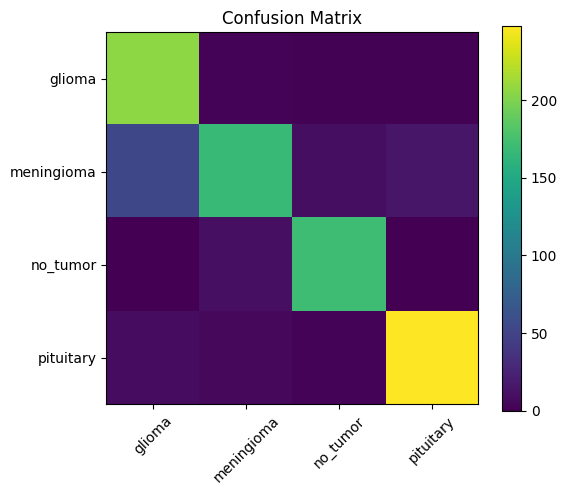

In [33]:
#Classification report + Confusion Matrix (TEST set)
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

cls_model.load_state_dict(torch.load("encoder_classifier_best.pt", map_location=device))
cls_model.eval()

all_y = []
all_p = []

with torch.no_grad():
    for x,y in test_cls_loader:
        x = x.to(device)
        logits = cls_model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        all_p.extend(pred)
        all_y.extend(y.numpy())

print(classification_report(all_y, all_p, target_names=label_names, digits=4))

cm = confusion_matrix(all_y, all_p)
plt.figure(figsize=(6,5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xticks(range(num_classes), label_names, rotation=45)
plt.yticks(range(num_classes), label_names)
plt.colorbar()
plt.show()


In [34]:
#Load models (Seg + Cls) + inference function
import matplotlib.pyplot as plt
import numpy as np
import cv2, os
import torch
import torchvision.transforms as T

# --- Load Segmentation Model (best) ---
seg_model = UNet(in_channels=3, out_channels=1).to(device)
seg_model.load_state_dict(torch.load("unet_seg_best.pt", map_location=device))
seg_model.eval()

# --- Load Classification Model (best) ---
cls_model = EncoderClassifier(num_classes=num_classes).to(device)
cls_model.load_state_dict(torch.load("encoder_classifier_best.pt", map_location=device))
cls_model.eval()

infer_tf = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor()
])

def infer_any_image(image_path, show=True):
    # read image
    img = cv2.imread(image_path)
    if img is None:
        print("❌ Image not found:", image_path)
        return
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    x = infer_tf(img_rgb).unsqueeze(0).to(device)

    # --- Segmentation ---
    with torch.no_grad():
        seg_logits = seg_model(x)
        seg_prob = torch.sigmoid(seg_logits)[0,0].cpu().numpy()
        seg_mask = (seg_prob > 0.5).astype(np.uint8)

    # --- Classification ---
    with torch.no_grad():
        cls_logits = cls_model(x)
        probs = torch.softmax(cls_logits, dim=1)[0].cpu().numpy()
        pred_id = int(probs.argmax())
        pred_label = id2label[pred_id]
        conf = float(probs[pred_id])

    if show:
        img_show = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
        plt.figure(figsize=(12,4))

        plt.subplot(1,3,1)
        plt.imshow(img_show); plt.title("Input"); plt.axis("off")

        plt.subplot(1,3,2)
        plt.imshow(seg_mask, cmap="gray"); plt.title("Pred Mask"); plt.axis("off")

        plt.subplot(1,3,3)
        plt.imshow(img_show)
        plt.imshow(seg_mask, alpha=0.5, cmap="jet")
        plt.title(f"Overlay\nClass: {pred_label} ({conf:.2f})")
        plt.axis("off")

        plt.show()

    return {"pred_label": pred_label, "confidence": conf, "mask": seg_mask}



Running on: /kaggle/input/brisc2025/brisc2025/segmentation_task/train/images/brisc2025_train_04242_pi_co_t1.jpg


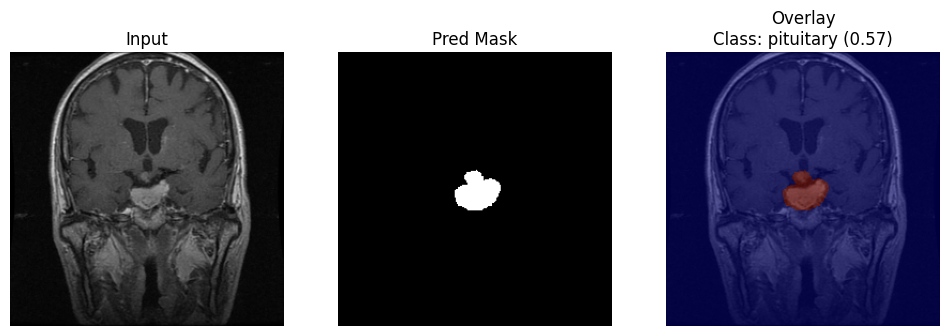

Running on: /kaggle/input/brisc2025/brisc2025/segmentation_task/train/images/brisc2025_train_00347_gl_ax_t1.jpg


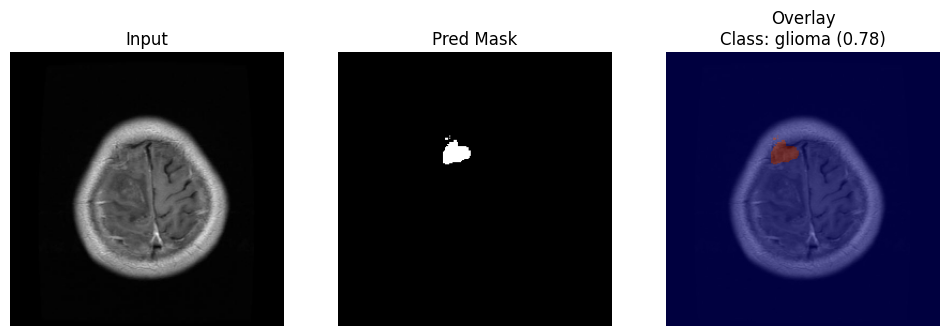

Running on: /kaggle/input/brisc2025/brisc2025/segmentation_task/train/images/brisc2025_train_02315_me_sa_t1.jpg


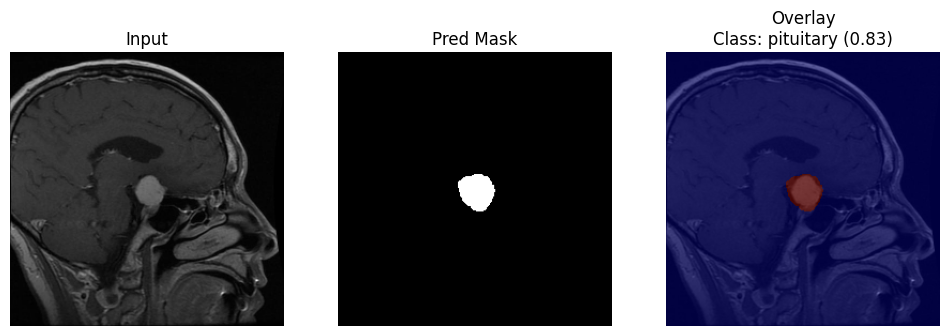

In [35]:
#Demo run (random image)
import random

# test_df segmentation dataframe থেকে random 3টা image
for _ in range(3):
    idx = random.randint(0, len(test_df)-1)
    img_path = os.path.join(base_path, test_df.iloc[idx]['relative_path_image'])
    print("Running on:", img_path)
    infer_any_image(img_path)


In [36]:
#Attention Gate + Attention U-Net
class AttentionGate(nn.Module):
    """
    Gating signal from decoder: g
    Skip connection from encoder: x
    Output: x * alpha
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        alpha = self.psi(psi)
        return x * alpha


class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64,128,256,512]):
        super().__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.att = nn.ModuleList()
        self.pool = nn.MaxPool2d(2,2)

        ch = in_channels
        for f in features:
            self.downs.append(DoubleConv(ch, f))
            ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1]*2)

        # decoder: upsample + attention gate + double conv
        for f in reversed(features):
            self.ups.append(nn.ConvTranspose2d(f*2, f, kernel_size=2, stride=2))
            # attention gate: gating from decoder (f), skip from encoder (f)
            self.att.append(AttentionGate(F_g=f, F_l=f, F_int=f//2))
            self.ups.append(DoubleConv(f*2, f))

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skips = []

        for down in self.downs:
            x = down(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        att_i = 0
        for i in range(0, len(self.ups), 2):
            x = self.ups[i](x)  # upsample
            skip = skips[i//2]

            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)

            # attention gate applied to skip
            skip = self.att[att_i](g=x, x=skip)
            att_i += 1

            x = torch.cat((skip, x), dim=1)
            x = self.ups[i+1](x)

        return self.final_conv(x)


In [37]:
#Train Attention U-Net (reuse same training loop)
att_model = AttentionUNet(in_channels=3, out_channels=1).to(device)
optimizer = torch.optim.Adam(att_model.parameters(), lr=1e-4)

EPOCHS_ATT = 8  # same as before (চাইলে 10)

att_history = {"train_loss":[], "val_loss":[], "train_dice":[], "val_dice":[], "train_iou":[], "val_iou":[]}

best_val_dice = -1

for epoch in range(1, EPOCHS_ATT+1):
    tr_loss, tr_dice, tr_iou, tr_acc = train_one_epoch(att_model, train_loader, optimizer)
    va_loss, va_dice, va_iou, va_acc = validate_one_epoch(att_model, val_loader)

    att_history["train_loss"].append(tr_loss); att_history["val_loss"].append(va_loss)
    att_history["train_dice"].append(tr_dice); att_history["val_dice"].append(va_dice)
    att_history["train_iou"].append(tr_iou);   att_history["val_iou"].append(va_iou)

    print(f"[ATT] Epoch {epoch}/{EPOCHS_ATT} | "
          f"Train Loss {tr_loss:.4f} Dice {tr_dice:.4f} IoU {tr_iou:.4f} || "
          f"Val Loss {va_loss:.4f} Dice {va_dice:.4f} IoU {va_iou:.4f}")

    if va_dice > best_val_dice:
        best_val_dice = va_dice
        torch.save(att_model.state_dict(), "attention_unet_best.pt")
        print("✅ Saved: attention_unet_best.pt")


[ATT] Epoch 1/8 | Train Loss 1.1051 Dice 0.2385 IoU 0.1683 || Val Loss 0.9778 Dice 0.2807 IoU 0.2180
✅ Saved: attention_unet_best.pt


[ATT] Epoch 2/8 | Train Loss 0.8642 Dice 0.3569 IoU 0.2617 || Val Loss 0.6693 Dice 0.5199 IoU 0.4136
✅ Saved: attention_unet_best.pt


[ATT] Epoch 3/8 | Train Loss 0.7399 Dice 0.4019 IoU 0.3034 || Val Loss 0.5022 Dice 0.6025 IoU 0.4913
✅ Saved: attention_unet_best.pt


[ATT] Epoch 4/8 | Train Loss 0.6893 Dice 0.4254 IoU 0.3287 || Val Loss 0.4944 Dice 0.6033 IoU 0.4884
✅ Saved: attention_unet_best.pt


[ATT] Epoch 5/8 | Train Loss 0.6762 Dice 0.4311 IoU 0.3345 || Val Loss 0.4354 Dice 0.6512 IoU 0.5408
✅ Saved: attention_unet_best.pt


[ATT] Epoch 6/8 | Train Loss 0.6639 Dice 0.4390 IoU 0.3430 || Val Loss 0.4580 Dice 0.6384 IoU 0.5238


[ATT] Epoch 7/8 | Train Loss 0.6463 Dice 0.4530 IoU 0.3536 || Val Loss 0.4168 Dice 0.6616 IoU 0.5482
✅ Saved: attention_unet_best.pt


[ATT] Epoch 8/8 | Train Loss 0.6423 Dice 0.4547 IoU 0.3550 || Val Loss 0.3825 Dice 0.6865 IoU 0.5723
✅ Saved: attention_unet_best.pt
